# OCEL event log analysis

A starting point for exploring OCEL 2.0 logs with [PM4Py](https://pm4py.fit.fraunhofer.de/). The default input is `logs/cohort-journey.ocel.json`, the primary cohort log (280 patients, 10,364 events). Change `LOG_PATH` below to analyse another log. This notebook reports aggregate counts only; it does not display patient-level records.

## Import PM4Py and load a log

If PM4Py is not available in the selected notebook environment, install it there first with `%pip install pm4py`, then restart the kernel.

In [33]:
import json
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import pm4py
from IPython.display import display

In [2]:
LOG_PATH = Path("logs/cohort-journey.ocel.json")

if not LOG_PATH.is_file():
    raise FileNotFoundError(
        f"OCEL log not found: {LOG_PATH.resolve()}\n"
        "Set LOG_PATH to the path of an OCEL 2 JSON file. "
        "Run this notebook from the repository root for the default path."
    )

ocel = pm4py.read_ocel2_json(str(LOG_PATH))
print(f"Loaded: {LOG_PATH}")

Loaded: logs/cohort-journey.ocel.json


## Basic statistics

The summary counts activities and object types without showing individual event or object records. PM4Py's imported object table may exclude objects that have no event relationships, so its object count can be lower than the total in the source JSON.

In [3]:
summary = {
    "PM4Py version": pm4py.__version__,
    "Events": len(ocel.events),
    "Objects in PM4Py log": len(ocel.objects),
    "Event types": ocel.events[ocel.event_activity].nunique(),
    "Object types": ocel.objects[ocel.object_type_column].nunique(),
    "Event-object relationships": len(ocel.relations),
}
display(summary)

{'PM4Py version': '2.7.23.12',
 'Events': 10364,
 'Objects in PM4Py log': 10935,
 'Event types': 30,
 'Object types': 13,
 'Event-object relationships': 29875}

In [4]:
events_by_type = (
    ocel.events[ocel.event_activity]
    .value_counts()
    .rename_axis("Event type")
    .reset_index(name="Events")
)

objects_by_type = (
    ocel.objects[ocel.object_type_column]
    .value_counts()
    .rename_axis("Object type")
    .reset_index(name="Objects")
)

display(events_by_type)
display(objects_by_type)

,Event type,Events
0,VisitHcp,2376
1,StartTreatment,1604
2,StartSymptom,1087
3,UndergoDiagnosticProcedure,968
4,ReceiveDiagnosis,644
5,ChangeTreatment,500
6,StartAdverseEvent,368
7,ReachDiagnosis,278
8,ReachSpecialistReferral,276
9,ReachDiagnosticWorkup,272


,Object type,Objects
0,HcpVisit,2376
1,Milestone,2000
2,Treatment,1638
3,Symptom,1087
4,DiagnosticProcedure,968
5,TreatmentCourse,705
6,Diagnosis,644
7,PatientCondition,642
8,AdverseEvent,368
9,Patient,280


## Step 1: Shape of the cohort

The journey log holds two kinds of events. **Fact events** record what happened (`StartTreatment`, `VisitHcp`, ...). **Milestone events** (`Reach*`, such as `ReachDiagnosis`) mark stages of the journey summary and are dated by the facts they summarise. Keep the two apart in process maps, or each stage is counted twice.

The cell below tags each event with its kind and its patient. Later sections reuse the resulting `events` table.

In [5]:
ACT, TS, EID = ocel.event_activity, ocel.event_timestamp, ocel.event_id_column
OID, OTYPE = ocel.object_id_column, ocel.object_type_column

events = ocel.events.copy()
events["kind"] = events[ACT].str.startswith("Reach").map({True: "milestone", False: "fact"})

# Every event relates to exactly one Patient object (qualifier "concerns").
patient_rel = ocel.relations[ocel.relations[OTYPE] == "Patient"]
assert patient_rel.groupby(EID).size().eq(1).all(), "an event relates to more than one patient"
events["patient"] = events[EID].map(patient_rel.set_index(EID)[OID])

display({
    "Patients": events["patient"].nunique(),
    "Events without a patient": int(events["patient"].isna().sum()),
    "Fact events": int(events["kind"].eq("fact").sum()),
    "Milestone events": int(events["kind"].eq("milestone").sum()),
    "Fact activities": events.loc[events["kind"].eq("fact"), ACT].nunique(),
    "Milestone activities": events.loc[events["kind"].eq("milestone"), ACT].nunique(),
})

{'Patients': 280,
 'Events without a patient': 0,
 'Fact events': 8364,
 'Milestone events': 2000,
 'Fact activities': 15,
 'Milestone activities': 15}

### Events per patient

,count,mean,std,min,25%,50%,75%,max
kind,,,,,,,,
fact,280.0,29.9,11.1,6.0,22.0,28.0,37.0,62.0
milestone,280.0,7.1,1.6,4.0,6.0,7.0,8.0,12.0
all,280.0,37.0,11.9,12.0,29.0,35.0,45.0,71.0


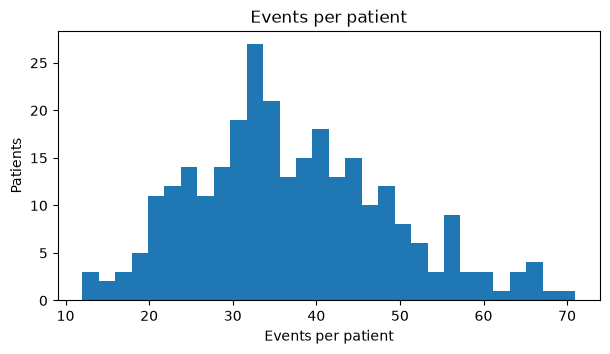

In [6]:
per_patient = events.groupby(["patient", "kind"]).size().unstack(fill_value=0)
per_patient["all"] = per_patient.sum(axis=1)
display(per_patient.describe().round(1).T)

fig, ax = plt.subplots(figsize=(7, 3.5))
per_patient["all"].plot.hist(bins=30, ax=ax)
ax.set(xlabel="Events per patient", ylabel="Patients", title="Events per patient")
plt.show()

### Events over time

Events are on occurrence time: when something happened to the patient, not when it was reported. A journey can start decades before the patient reported it, so the early years come from recalled history.

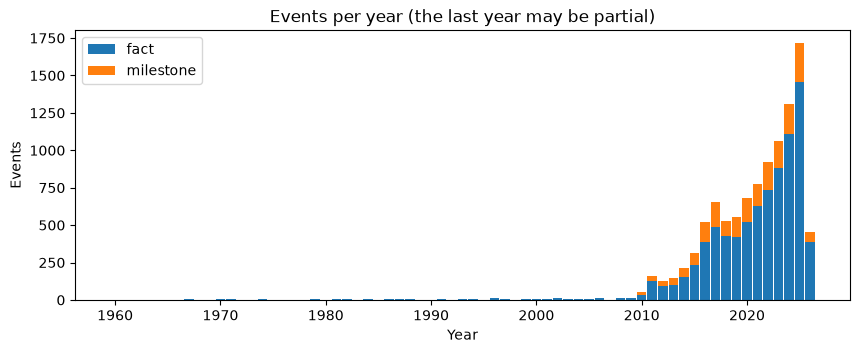

,First event (year),Journey span (years)
count,280.0,280.0
mean,2010.7,14.0
std,14.1,14.2
min,1960.0,0.2
25%,2006.0,4.4
50%,2015.0,9.0
75%,2020.0,18.9
max,2026.0,66.0


{'Last event in the log': '2026-10-02'}

In [7]:
events["year"] = events[TS].dt.year
by_year = (
    events.groupby(["year", "kind"]).size().unstack(fill_value=0)
    .reindex(range(events["year"].min(), events["year"].max() + 1), fill_value=0)
)

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.bar(by_year.index, by_year["fact"], width=0.9, label="fact")
ax.bar(by_year.index, by_year["milestone"], bottom=by_year["fact"], width=0.9, label="milestone")
ax.set(xlabel="Year", ylabel="Events", title="Events per year (the last year may be partial)")
ax.legend()
plt.show()

span = events.groupby("patient")[TS].agg(["min", "max"])
display(pd.DataFrame({
    "First event (year)": span["min"].dt.year.describe(),
    "Journey span (years)": ((span["max"] - span["min"]).dt.days / 365.25).describe(),
}).round(1))
display({"Last event in the log": str(events[TS].max().date())})

### Date precision

`precision` says how exactly a date is known. An event known only to the month is placed on the first day of that month (the build parameter `time_anchor=lower`), so events of the same patient often share a timestamp. Their order within that timestamp is arbitrary, and a directly-follows relation between them is not observed. The tie rates at the end show how much of the log this affects; keep it in mind when reading process maps.

In [8]:
PRECISION_ORDER = ["day", "week", "month", "quarter", "year", "before", "missing"]
precision = events["precision"].fillna("missing")
levels = [p for p in PRECISION_ORDER if p in set(precision)]

overall = precision.value_counts().reindex(levels)
display(pd.DataFrame({"Events": overall, "Share (%)": (100 * overall / overall.sum()).round(1)}))

precision_by_activity = (
    pd.crosstab(events[ACT], precision, normalize="index")
    .reindex(columns=levels)
    .mul(100)
    .round(0)
)
precision_by_activity.insert(0, "Events", events[ACT].value_counts())
display(precision_by_activity.sort_values("Events", ascending=False))


def share_with_tied_timestamp(df):
    """Percentage of events whose patient has another event at the same timestamp."""
    tied = df.groupby(["patient", TS])[EID].transform("size") > 1
    return round(100 * float(tied.mean()), 1)


display({
    "Tied timestamps, all events (%)": share_with_tied_timestamp(events),
    "Tied timestamps, fact events only (%)": share_with_tied_timestamp(events[events["kind"].eq("fact")]),
    "Tied timestamps, milestone events only (%)": share_with_tied_timestamp(events[events["kind"].eq("milestone")]),
})

,Events,Share (%)
precision,,
day,2136,20.6
week,519,5.0
month,6313,60.9
quarter,1276,12.3
year,86,0.8
before,3,0.0
missing,31,0.3


precision,Events,day,week,month,quarter,year,before,missing
ocel:activity,,,,,,,,
VisitHcp,2376,21.0,5.0,61.0,14.0,0.0,0.0,0.0
StartTreatment,1604,20.0,7.0,60.0,12.0,1.0,0.0,0.0
StartSymptom,1087,21.0,6.0,58.0,13.0,3.0,0.0,0.0
UndergoDiagnosticProcedure,968,19.0,4.0,61.0,15.0,0.0,0.0,0.0
ReceiveDiagnosis,644,17.0,1.0,71.0,9.0,2.0,0.0,0.0
ChangeTreatment,500,18.0,7.0,55.0,12.0,1.0,1.0,6.0
StartAdverseEvent,368,20.0,5.0,60.0,15.0,0.0,0.0,0.0
ReachDiagnosis,278,17.0,0.0,79.0,3.0,0.0,0.0,0.0
ReachSpecialistReferral,276,21.0,4.0,59.0,15.0,0.0,0.0,0.0


{'Tied timestamps, all events (%)': 67.0,
 'Tied timestamps, fact events only (%)': 48.8,
 'Tied timestamps, milestone events only (%)': 40.7}

### Who reported the journey, and who the patients are

An event's `resource` says who reported it: the patient or a caregiver. The first table checks whether a journey is reported by one of them throughout or by both. The rest describe the cohort from the `Patient` and `PatientCondition` objects.

In [9]:
caregiver_share = events.groupby("patient")["resource"].agg(lambda s: s.eq("caregiver").mean())
reported_by = pd.cut(caregiver_share, [-0.01, 0, 0.999, 1], labels=["patient only", "mixed", "caregiver only"])
display(reported_by.value_counts().rename_axis("Journey reported by").reset_index(name="Patients"))

patients = ocel.objects[ocel.objects[OTYPE] == "Patient"]
display(patients["sex"].value_counts(dropna=False).rename_axis("Sex").reset_index(name="Patients"))
display(patients["country"].value_counts(dropna=False).rename_axis("Country").reset_index(name="Patients"))
birth_decade = (patients["birth_year"] // 10 * 10).astype("Int64")
display(birth_decade.value_counts().sort_index().rename_axis("Birth decade").reset_index(name="Patients"))

conditions = ocel.objects[ocel.objects[OTYPE] == "PatientCondition"]
mg = conditions[conditions["condition_code"].eq("conditions.myasthenia_gravis")]
display({"Myasthenia gravis condition objects": len(mg)})
display(mg["serostatus"].value_counts(dropna=False).rename_axis("Serostatus (MG)").reset_index(name="Patients"))

,Journey reported by,Patients
0,patient only,226
1,caregiver only,54
2,mixed,0


,Sex,Patients
0,FEMALE,154
1,MALE,126


,Country,Patients
0,DEU,158
1,ESP,23
2,ITA,19
3,AUT,18
4,NLD,18
5,CHE,16
6,FRA,12
7,PRT,11
8,POL,5


,Birth decade,Patients
0,1930,11
1,1940,46
2,1950,43
3,1960,47
4,1970,34
5,1980,52
6,1990,37
7,2000,10


{'Myasthenia gravis condition objects': 280}

,Serostatus (MG),Patients
0,achr_positive,217
1,seronegative,30
2,musk_positive,18
3,NaN,9
4,other_seropositive,6


## Step 2: Path to diagnosis (milestones)

Each journey stage is a `Milestone` object (one per patient and stage). It has a `Reach*` event only when it is dated. The journey summary also links milestones in its own order through `followed_by`. PM4Py drops objects that have no events, and with them the undated and not-reached milestones, so this section reads them from the JSON file directly.

The resulting `milestones` table has one row per milestone: its patient, type, presence, timestamp, date range (`date_from` to `date_to`, end exclusive) and position in the `followed_by` chain.

In [10]:
raw = json.loads(LOG_PATH.read_text())


def attrs(item):
    """Attribute values of an OCEL item; for objects, the latest value of each attribute."""
    return {a["name"]: a["value"] for a in item.get("attributes", [])}


def related(item, qualifier):
    return [r["objectId"] for r in item.get("relationships", []) if r["qualifier"] == qualifier]


patient_of_condition = {
    o["id"]: related(o, "of_patient")[0] for o in raw["objects"] if o["type"] == "PatientCondition"
}
milestone_event = {
    related(e, "subject")[0]: e for e in raw["events"] if e["type"].startswith("Reach")
}

rows = []
for o in raw["objects"]:
    if o["type"] != "Milestone":
        continue
    a = attrs(o)
    e = milestone_event.get(o["id"])
    ea = attrs(e) if e else {}
    rows.append({
        "milestone": o["id"],
        "patient": patient_of_condition[related(o, "in_journey")[0]],
        "type": a["milestone_type"],
        "presence": a.get("presence"),
        "time": pd.Timestamp(e["time"]) if e else pd.NaT,
        "precision": ea.get("precision"),
        "date_from": pd.Timestamp(ea["clinical_from"], tz="UTC") if e else pd.NaT,
        "date_to": pd.Timestamp(ea["clinical_to"], tz="UTC") if e else pd.NaT,
        "next": (related(o, "followed_by") or [None])[0],
    })
milestones = pd.DataFrame(rows).set_index("milestone")
assert not milestones.duplicated(["patient", "type"]).any(), "a patient has two milestones of one type"

# Position of each milestone in its followed_by chain (the journey summary's own order).
successor = milestones["next"].dropna().to_dict()
chain_pos = {}
for head in set(milestones.index) - set(successor.values()):
    pos, m = 0, head
    while m is not None:
        chain_pos[m] = pos
        pos, m = pos + 1, successor.get(m)
milestones["chain_pos"] = pd.Series(chain_pos)

STAGE_ORDER = [
    "SYMPTOM_ONSET", "INFORMATION_SEARCH", "FIRST_HCP_VISIT", "EMERGENCY_PRESENTATION",
    "SPECIALIST_REFERRAL", "DIAGNOSTIC_WORKUP", "MISDIAGNOSIS", "DIAGNOSIS",
    "CONVENTIONAL_THERAPY", "SOCIAL_CONSULTATION", "HOSPITALIZATION", "MYASTHENIC_CRISIS",
    "RESCUE_THERAPY", "THYMECTOMY", "ADVANCED_THERAPY",
]
milestones["stage_rank"] = milestones["type"].map({t: i for i, t in enumerate(STAGE_ORDER)})
assert milestones["stage_rank"].notna().all(), "a milestone type is missing from STAGE_ORDER"

n_patients = milestones["patient"].nunique()
display({
    "Patients": n_patients,
    "Milestone objects": len(milestones),
    "Dated (with a Reach* event)": int(milestones["time"].notna().sum()),
    "Reached, no date": int((milestones["presence"].eq("reached") & milestones["time"].isna()).sum()),
    "Not reached": int(milestones["presence"].eq("not_reached").sum()),
})

{'Patients': 280,
 'Milestone objects': 2267,
 'Dated (with a Reach* event)': 2000,
 'Reached, no date': 157,
 'Not reached': 110}

### Which milestones the patients reached

Patients per milestone type. *Reached, no date*: the summary says it happened but gives no usable date, so there is no event. *Not reached*: the summary records that it did not happen. *No record*: the summary does not mention it.

In [11]:
status = pd.Series("dated", index=milestones.index)
status[milestones["time"].isna() & milestones["presence"].eq("reached")] = "reached, no date"
status[milestones["presence"].eq("not_reached")] = "not reached"
coverage = (
    pd.crosstab(milestones["type"], status)
    .reindex(index=STAGE_ORDER, columns=["dated", "reached, no date", "not reached"], fill_value=0)
)
coverage["no record"] = n_patients - coverage.sum(axis=1)
coverage["dated (%)"] = (100 * coverage["dated"] / n_patients).round(0)
display(coverage.rename_axis(index="Milestone", columns=None))

,dated,"reached, no date",not reached,no record,dated (%)
Milestone,,,,,
SYMPTOM_ONSET,252,27,0,1,90.0
INFORMATION_SEARCH,12,24,0,244,4.0
FIRST_HCP_VISIT,255,25,0,0,91.0
EMERGENCY_PRESENTATION,35,2,0,243,12.0
SPECIALIST_REFERRAL,276,2,0,2,99.0
DIAGNOSTIC_WORKUP,272,2,0,6,97.0
MISDIAGNOSIS,61,7,0,212,22.0
DIAGNOSIS,278,1,1,0,99.0
CONVENTIONAL_THERAPY,261,11,0,8,93.0


### The summary's order against the dates

The `followed_by` links give the journey summary's own order of milestones. This checks it against the timestamps. A reversed link is *within date uncertainty* when the two date ranges overlap, so the dates cannot settle the order. It is *beyond* when the later milestone's whole range ends before the earlier one's begins.

In [12]:
links = (
    milestones[["next", "type", "time", "date_from", "date_to"]].dropna(subset=["next"])
    .merge(milestones[["type", "time", "date_from", "date_to"]], left_on="next", right_index=True,
           suffixes=("", "_next"))
)
links["order"] = "undated"
dated = links["time"].notna() & links["time_next"].notna()
links.loc[dated & (links["time"] < links["time_next"]), "order"] = "forward in time"
links.loc[dated & (links["time"] == links["time_next"]), "order"] = "same timestamp"
reversed_ = dated & (links["time"] > links["time_next"])
overlap = links["date_to_next"] > links["date_from"]
links.loc[reversed_ & overlap, "order"] = "reversed, within date uncertainty"
links.loc[reversed_ & ~overlap, "order"] = "reversed, beyond date uncertainty"
display(links["order"].value_counts().rename_axis("followed_by link").reset_index(name="Links"))

display(
    links[links["order"].str.startswith("reversed")]
    .groupby(["type", "type_next", "order"]).size().unstack(fill_value=0)
    .assign(total=lambda df: df.sum(axis=1)).sort_values("total", ascending=False)
    .rename_axis(["From", "To"]).head(10)
)

,followed_by link,Links
0,forward in time,1060
1,same timestamp,305
2,"reversed, within date uncertainty",106
3,undated,86
4,"reversed, beyond date uncertainty",31


,order,"reversed, beyond date uncertainty","reversed, within date uncertainty",total
From,To,,,
DIAGNOSIS,CONVENTIONAL_THERAPY,2,37,39
SPECIALIST_REFERRAL,DIAGNOSTIC_WORKUP,14,22,36
SYMPTOM_ONSET,FIRST_HCP_VISIT,5,17,22
DIAGNOSTIC_WORKUP,DIAGNOSIS,6,5,11
FIRST_HCP_VISIT,SPECIALIST_REFERRAL,0,6,6
DIAGNOSTIC_WORKUP,MISDIAGNOSIS,0,4,4
MYASTHENIC_CRISIS,RESCUE_THERAPY,0,4,4
SPECIALIST_REFERRAL,MISDIAGNOSIS,0,4,4
CONVENTIONAL_THERAPY,MYASTHENIC_CRISIS,2,0,2


### Milestone variants

Each patient's dated milestones are ordered by timestamp. Ties are broken by position in the `followed_by` chain, then by the stage order in `STAGE_ORDER`. The first table cuts each sequence after `DIAGNOSIS`: the path to diagnosis. The second shows whole sequences. Variants followed by fewer than `MIN_PATIENTS` patients are pooled, so no table row describes a single patient.

In [13]:
MIN_PATIENTS = 5  # report a variant only if at least this many patients follow it

ordered = (
    milestones[milestones["time"].notna()]
    .sort_values(["patient", "time", "chain_pos", "stage_rank"], na_position="last")
)
sequences = ordered.groupby("patient")["type"].agg(tuple)


def to_diagnosis(seq):
    """The part of a sequence up to and including DIAGNOSIS."""
    return seq[: seq.index("DIAGNOSIS") + 1] if "DIAGNOSIS" in seq else seq


def variant_table(seqs, min_patients=MIN_PATIENTS):
    counts = seqs.map(" → ".join).value_counts()
    shown = counts[counts >= min_patients]
    rest = counts[counts < min_patients]
    table = shown.rename_axis("Variant").reset_index(name="Patients")
    table.loc[len(table)] = [f"other ({len(rest)} variants)", rest.sum()]
    table["Share (%)"] = (100 * table["Patients"] / counts.sum()).round(1)
    return counts.size, table


n_full, full_table = variant_table(sequences)
n_dx, dx_table = variant_table(sequences.map(to_diagnosis))
display({
    "Variants, whole milestone sequence": n_full,
    "Variants, sequence up to diagnosis": n_dx,
    "Patients without a dated DIAGNOSIS": int((~sequences.map(lambda s: "DIAGNOSIS" in s)).sum()),
})
with pd.option_context("display.max_colwidth", None):
    display(dx_table)
    display(full_table)

{'Variants, whole milestone sequence': 168,
 'Variants, sequence up to diagnosis': 84,
 'Patients without a dated DIAGNOSIS': 2}

,Variant,Patients,Share (%)
0,SYMPTOM_ONSET → FIRST_HCP_VISIT → SPECIALIST_REFERRAL → DIAGNOSTIC_WORKUP → DIAGNOSIS,85,30.4
1,SYMPTOM_ONSET → FIRST_HCP_VISIT → MISDIAGNOSIS → SPECIALIST_REFERRAL → DIAGNOSTIC_WORKUP → DIAGNOSIS,15,5.4
2,SYMPTOM_ONSET → FIRST_HCP_VISIT → SPECIALIST_REFERRAL → MISDIAGNOSIS → DIAGNOSTIC_WORKUP → DIAGNOSIS,15,5.4
3,SYMPTOM_ONSET → FIRST_HCP_VISIT → SPECIALIST_REFERRAL → DIAGNOSTIC_WORKUP → CONVENTIONAL_THERAPY → DIAGNOSIS,14,5.0
4,SYMPTOM_ONSET → FIRST_HCP_VISIT → DIAGNOSTIC_WORKUP → SPECIALIST_REFERRAL → DIAGNOSIS,11,3.9
5,FIRST_HCP_VISIT → SPECIALIST_REFERRAL → DIAGNOSTIC_WORKUP → DIAGNOSIS,11,3.9
6,SYMPTOM_ONSET → SPECIALIST_REFERRAL → DIAGNOSTIC_WORKUP → DIAGNOSIS,8,2.9
7,FIRST_HCP_VISIT → SYMPTOM_ONSET → SPECIALIST_REFERRAL → DIAGNOSTIC_WORKUP → DIAGNOSIS,7,2.5
8,SYMPTOM_ONSET → FIRST_HCP_VISIT → EMERGENCY_PRESENTATION → DIAGNOSTIC_WORKUP → SPECIALIST_REFERRAL → DIAGNOSIS,6,2.1
9,SYMPTOM_ONSET → FIRST_HCP_VISIT → SPECIALIST_REFERRAL → DIAGNOSIS,6,2.1


,Variant,Patients,Share (%)
0,SYMPTOM_ONSET → FIRST_HCP_VISIT → SPECIALIST_REFERRAL → DIAGNOSTIC_WORKUP → DIAGNOSIS → CONVENTIONAL_THERAPY,40,14.3
1,SYMPTOM_ONSET → FIRST_HCP_VISIT → SPECIALIST_REFERRAL → MISDIAGNOSIS → DIAGNOSTIC_WORKUP → DIAGNOSIS → CONVENTIONAL_THERAPY,12,4.3
2,SYMPTOM_ONSET → FIRST_HCP_VISIT → SPECIALIST_REFERRAL → DIAGNOSTIC_WORKUP → CONVENTIONAL_THERAPY → DIAGNOSIS,10,3.6
3,SYMPTOM_ONSET → FIRST_HCP_VISIT → SPECIALIST_REFERRAL → DIAGNOSTIC_WORKUP → DIAGNOSIS → CONVENTIONAL_THERAPY → HOSPITALIZATION → THYMECTOMY,8,2.9
4,SYMPTOM_ONSET → FIRST_HCP_VISIT → MISDIAGNOSIS → SPECIALIST_REFERRAL → DIAGNOSTIC_WORKUP → DIAGNOSIS → CONVENTIONAL_THERAPY,7,2.5
5,FIRST_HCP_VISIT → SYMPTOM_ONSET → SPECIALIST_REFERRAL → DIAGNOSTIC_WORKUP → DIAGNOSIS → CONVENTIONAL_THERAPY,6,2.1
6,SYMPTOM_ONSET → FIRST_HCP_VISIT → SPECIALIST_REFERRAL → DIAGNOSTIC_WORKUP → DIAGNOSIS → CONVENTIONAL_THERAPY → HOSPITALIZATION → MYASTHENIC_CRISIS → RESCUE_THERAPY,5,1.8
7,FIRST_HCP_VISIT → SPECIALIST_REFERRAL → DIAGNOSTIC_WORKUP → DIAGNOSIS → CONVENTIONAL_THERAPY,5,1.8
8,other (160 variants),187,66.8


### Directly-follows graph of milestones

Built from the ordered sequences above (one case per patient), so it uses the same tie-breaking rule. Edges seen fewer than `MIN_EDGE` times are hidden.

{'Directly-follows edges': 101,
 'Edges with at least 5 occurrences (shown)': 45,
 'Milestone types hidden by the threshold': ['INFORMATION_SEARCH']}

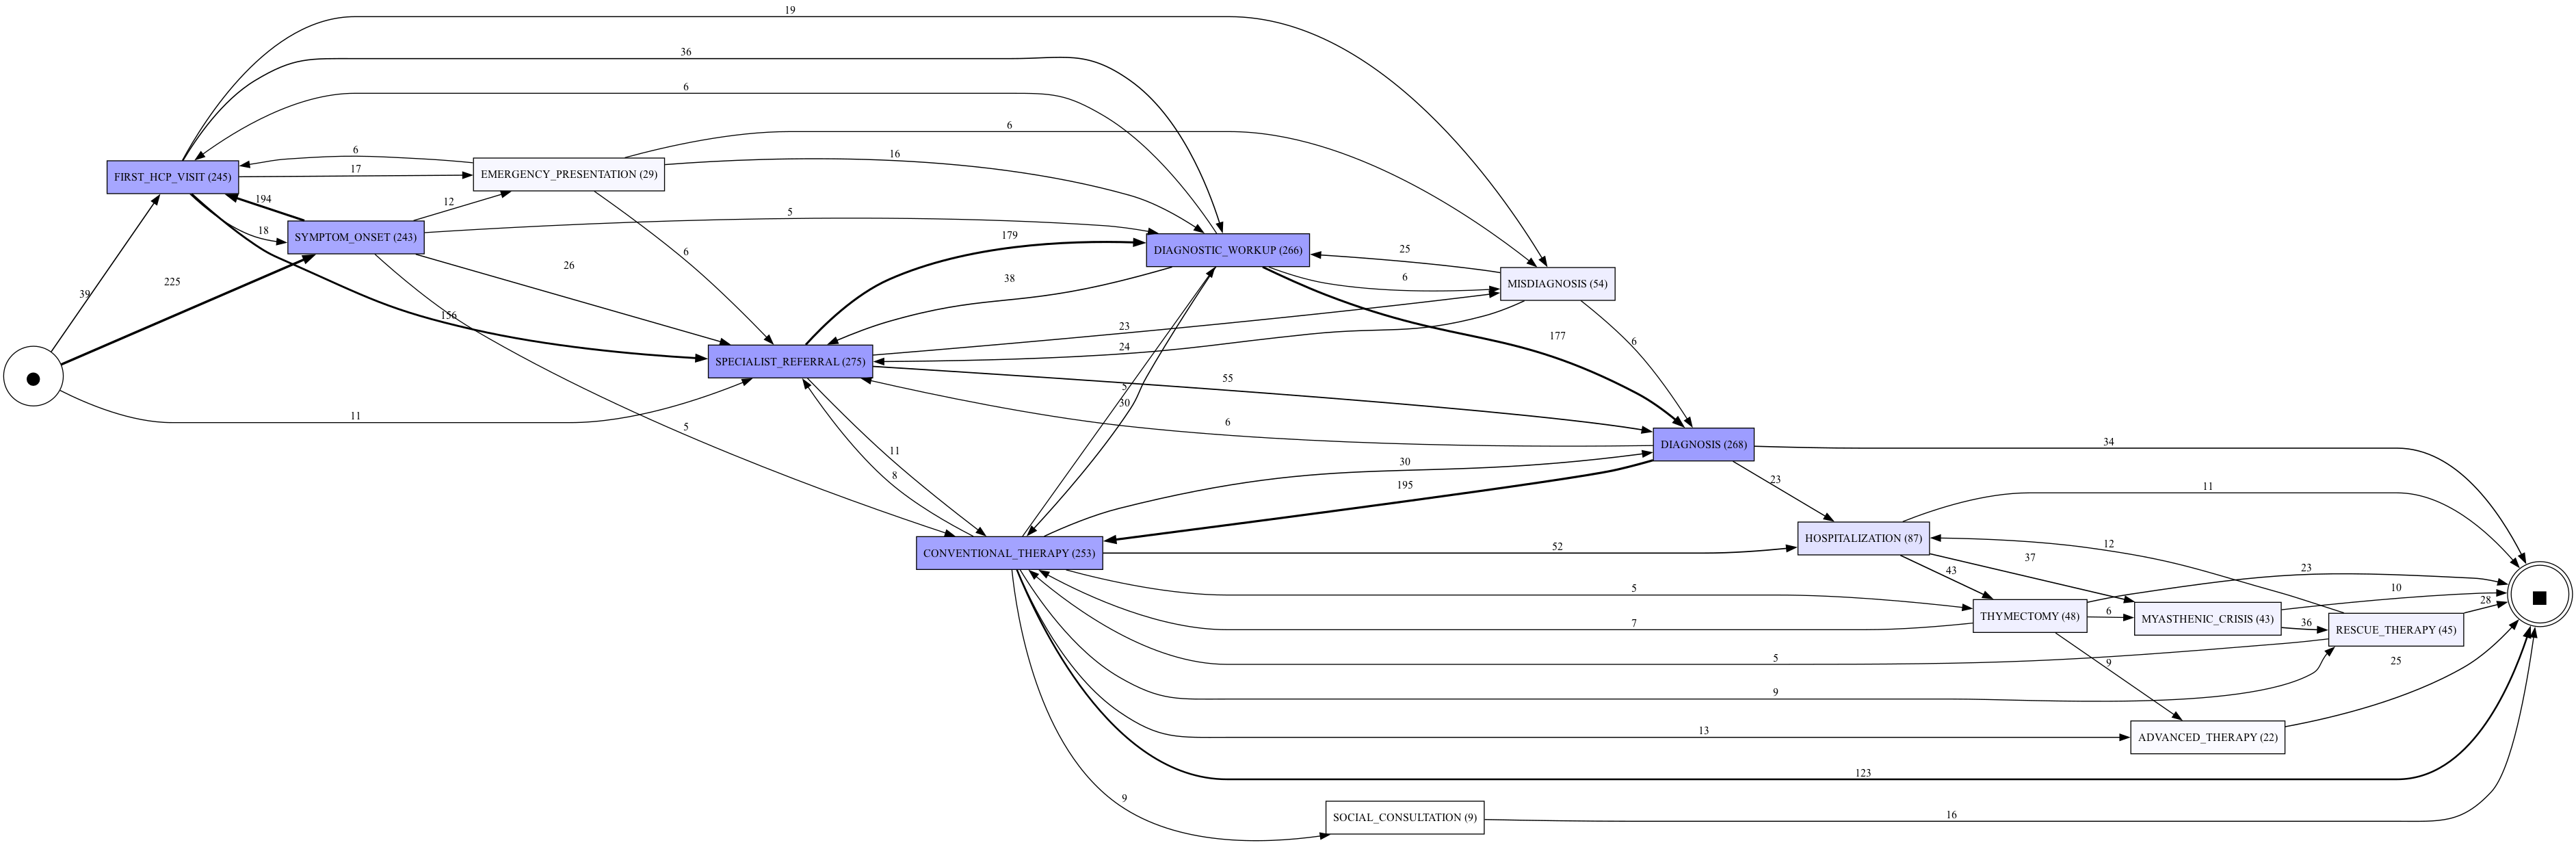

In [14]:
MIN_EDGE = 5  # hide directly-follows edges seen in fewer patients than this

dfg = Counter(pair for seq in sequences for pair in zip(seq, seq[1:]))
start_activities = Counter(seq[0] for seq in sequences)
end_activities = Counter(seq[-1] for seq in sequences)

shown_dfg = {edge: n for edge, n in dfg.items() if n >= MIN_EDGE}
shown_nodes = {node for edge in shown_dfg for node in edge}
display({
    "Directly-follows edges": len(dfg),
    f"Edges with at least {MIN_EDGE} occurrences (shown)": len(shown_dfg),
    "Milestone types hidden by the threshold": sorted(set(milestones["type"]) - shown_nodes),
})
# PNG, not SVG: in a notebook PM4Py displays the graph with IPython's Image, which cannot embed SVG.
pm4py.view_dfg(
    shown_dfg,
    {a: n for a, n in start_activities.items() if a in shown_nodes and n >= MIN_EDGE},
    {a: n for a, n in end_activities.items() if a in shown_nodes and n >= MIN_EDGE},
    format="png",
)

### Time between milestones

For each step, among patients with both milestones dated: the gap between their timestamps, then the median of the shortest and longest gap their date ranges allow. A wide spread between shortest and longest means the dates are too coarse to measure that step well. *Negative* is the share of patients for whom the later stage is dated before the earlier one.

In [15]:
STEPS = [
    ("SYMPTOM_ONSET", "FIRST_HCP_VISIT"),
    ("FIRST_HCP_VISIT", "SPECIALIST_REFERRAL"),
    ("SPECIALIST_REFERRAL", "DIAGNOSTIC_WORKUP"),
    ("DIAGNOSTIC_WORKUP", "DIAGNOSIS"),
    ("DIAGNOSIS", "CONVENTIONAL_THERAPY"),
    ("SYMPTOM_ONSET", "DIAGNOSIS"),
]
DAYS_PER_MONTH = 30.44

wide = {c: milestones.pivot(index="patient", columns="type", values=c) for c in ["time", "date_from", "date_to"]}


def months(delta):
    return delta.dt.days / DAYS_PER_MONTH


rows = []
for a, b in STEPS:
    both = wide["time"][[a, b]].dropna().index
    gap = months(wide["time"].loc[both, b] - wide["time"].loc[both, a])
    # Shortest and longest gap the date ranges allow (date_to is exclusive).
    shortest = months(wide["date_from"].loc[both, b] - wide["date_to"].loc[both, a]).clip(lower=0)
    longest = months(wide["date_to"].loc[both, b] - wide["date_from"].loc[both, a])
    rows.append({
        "Step": f"{a} → {b}",
        "Patients": len(both),
        "Median (months)": gap.median(),
        "Q1": gap.quantile(0.25),
        "Q3": gap.quantile(0.75),
        "Median shortest": shortest.median(),
        "Median longest": longest.median(),
        "Negative (%)": 100 * (gap < 0).mean(),
    })
display(pd.DataFrame(rows).set_index("Step").round(1))

,Patients,Median (months),Q1,Q3,Median shortest,Median longest,Negative (%)
Step,,,,,,,
SYMPTOM_ONSET → FIRST_HCP_VISIT,232,2.0,0.6,4.9,0.1,3.7,9.5
FIRST_HCP_VISIT → SPECIALIST_REFERRAL,251,3.0,1.0,6.0,1.7,4.8,2.4
SPECIALIST_REFERRAL → DIAGNOSTIC_WORKUP,268,0.0,0.0,3.0,0.0,2.3,19.8
DIAGNOSTIC_WORKUP → DIAGNOSIS,270,3.0,1.0,6.8,1.0,4.0,4.4
DIAGNOSIS → CONVENTIONAL_THERAPY,259,0.2,0.0,1.0,0.0,2.0,15.1
SYMPTOM_ONSET → DIAGNOSIS,251,12.7,7.0,18.3,10.1,13.8,2.4


### Diagnostic delay

Time from symptom onset to diagnosis, compared between patients who reached a dated milestone (misdiagnosis, emergency presentation) and those who did not. These are descriptive differences, not tested effects.

Patients    Q1  Median (months)    Q3
Milestone              Reached                                       
Misdiagnosis           no            194   6.0             10.6  16.3
                       yes            57  15.0             19.6  24.0
Emergency presentation no            218   7.0             12.9  18.6
                       yes            33   6.9             11.8  17.0

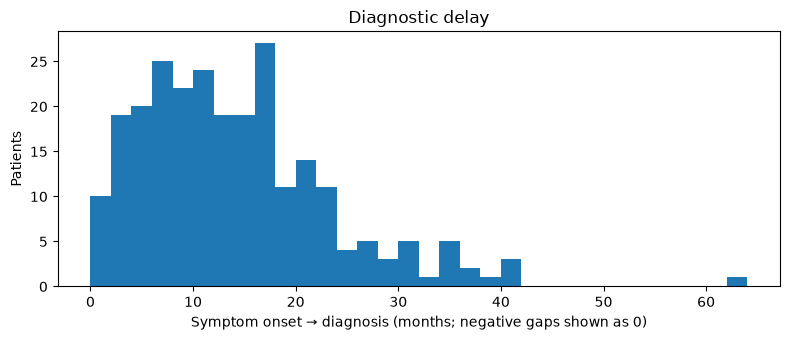

In [16]:
delay = months(wide["time"]["DIAGNOSIS"] - wide["time"]["SYMPTOM_ONSET"]).dropna()
dated_types = wide["time"].loc[delay.index].notna()

summary = pd.concat(
    {
        name: delay.groupby(dated_types[milestone].map({True: "yes", False: "no"}))
        .describe()[["count", "25%", "50%", "75%"]]
        for name, milestone in {"Misdiagnosis": "MISDIAGNOSIS", "Emergency presentation": "EMERGENCY_PRESENTATION"}.items()
    },
    names=["Milestone", "Reached"],
)
summary["count"] = summary["count"].astype(int)
display(summary.round(1).rename(columns={"count": "Patients", "25%": "Q1", "50%": "Median (months)", "75%": "Q3"}))

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(delay.clip(lower=0), bins=range(0, int(delay.max()) + 3, 2))
ax.set(
    xlabel="Symptom onset → diagnosis (months; negative gaps shown as 0)",
    ylabel="Patients",
    title="Diagnostic delay",
)
fig.tight_layout()
plt.show()

## Step 3: Treatment lines

A `TreatmentCourse` is one treatment in one patient's myasthenia gravis journey, such as pyridostigmine or a thymectomy. All courses belong to the MG journey. Medication for other conditions (such as methotrexate for rheumatoid arthritis) is not in a course and is left out of this step.

A course is made of treatment periods (`Treatment` objects linked by `in_course`). A period begins with `StartTreatment` and ends in one of four ways:

- **changed**: `ChangeTreatment`. The dose or schedule changed, and the next period carries on.
- **stopped**: `EndTreatment`.
- **ended, undated**: no end event, but the period has an end reason, so it ended (or changed) on a date the sources don't give.
- **no end recorded**: ongoing when the patient reported it, or ended without a date or a reason.

`DRUG_CLASS` groups the drugs into treatment classes. The grouping is mine, not part of the log, so edit it if you group them differently. Drugs it does not list count as *other*: anaesthesia, vaccines, antibiotics, ventilation and medication MG patients should use with care.

In [17]:
DRUG_CLASS = {
    "treatments.pyridostigmine": "symptomatic",
    "treatments.prednisolone": "corticosteroid",
    "treatments.corticosteroids": "corticosteroid",
    "treatments.unspecified_corticosteroid": "corticosteroid",
    "treatments.azathioprine": "immunosuppressant",
    "treatments.mycophenolate_mofetil": "immunosuppressant",
    "treatments.thymectomy": "thymectomy",
    "treatments.ivig": "IVIG / plasma exchange",
    "treatments.unspecified_immunoglobulin": "IVIG / plasma exchange",
    "treatments.plasmapheresis": "IVIG / plasma exchange",
    "treatments.efgartigimod": "advanced",  # FcRn blocker
    "treatments.rozanolixizumab": "advanced",  # FcRn blocker
    "treatments.eculizumab": "advanced",  # complement inhibitor
    "treatments.ravulizumab": "advanced",  # complement inhibitor
    "treatments.zilucoplan": "advanced",  # complement inhibitor
    "treatments.rituximab": "advanced",  # B-cell depletion
}
CLASS_ORDER = [
    "symptomatic", "corticosteroid", "immunosuppressant", "thymectomy",
    "IVIG / plasma exchange", "advanced", "other",
]
END_EVENT = {"ChangeTreatment": "changed", "EndTreatment": "stopped"}

treatment_events = {}  # Treatment id -> {activity: event}
for e in raw["events"]:
    if e["type"] in ("StartTreatment", *END_EVENT):
        acts = treatment_events.setdefault(related(e, "subject")[0], {})
        assert e["type"] not in acts, "a treatment period has two events of one type"
        acts[e["type"]] = e

rows = []
for o in raw["objects"]:
    if o["type"] != "Treatment" or not related(o, "in_course"):
        continue
    evs = treatment_events.get(o["id"], {})
    start = evs.get("StartTreatment")
    end = evs.get("EndTreatment") or evs.get("ChangeTreatment")
    reasons = json.loads(attrs(o).get("end_reason_categories", "[]"))
    if end:
        end_type = END_EVENT[end["type"]]
    else:
        end_type = "ended, undated" if reasons else "no end recorded"
    rows.append({
        "period": o["id"],
        "course": related(o, "in_course")[0],
        "start": pd.Timestamp(start["time"]) if start else pd.NaT,
        "end": pd.Timestamp(end["time"]) if end else pd.NaT,
        "end_type": end_type,
        "end_reasons": reasons,
    })
# Order periods within a course by start, or by end when the start is not dated.
periods = (
    pd.DataFrame(rows)
    .assign(key=lambda d: d["start"].fillna(d["end"]))
    .sort_values(["course", "key"])
    .reset_index(drop=True)
)

courses = pd.DataFrame([
    {"course": o["id"], "patient": patient_of_condition[related(o, "in_journey")[0]],
     "drug": attrs(o)["treatment_code"]}
    for o in raw["objects"] if o["type"] == "TreatmentCourse"
]).set_index("course")
courses["class"] = courses["drug"].map(DRUG_CLASS).fillna("other")

by_course = periods.groupby("course")
last = by_course.tail(1).set_index("course")  # the latest period decides how the course ends
courses["periods"] = by_course.size()
courses["changes"] = by_course["end_type"].agg(lambda s: s.eq("changed").sum())
courses["stops"] = by_course["end_type"].agg(lambda s: s.eq("stopped").sum())
courses["start"] = by_course["start"].min()
courses["last_time"] = pd.concat([by_course["start"].max(), by_course["end"].max()], axis=1).max(axis=1)
# A course whose latest period changed carries on, so it has no end yet.
courses["outcome"] = last["end_type"].replace({"changed": "no end recorded"})
courses["end"] = last["end"].where(courses["outcome"].eq("stopped"))
courses["restarted"] = courses["stops"] > courses["outcome"].eq("stopped").astype(int)

# When each patient reported their journey: the latest report time of their events.
report_date = pd.to_datetime(events["reported_at"], utc=True).groupby(events["patient"]).max()

display({
    "Courses": len(courses),
    "Courses with a dated start": int(courses["start"].notna().sum()),
    "Patients with a course": courses["patient"].nunique(),
    "Treatment periods": len(periods),
    "Period ends": periods["end_type"].value_counts().to_dict(),
})

{'Courses': 747,
 'Courses with a dated start': 705,
 'Patients with a course': 273,
 'Treatment periods': 1582,
 'Period ends': {'no end recorded': 760,
  'changed': 493,
  'stopped': 169,
  'ended, undated': 160}}

### Courses by treatment class

Patients and courses per class, and how the courses run. *Restarted*: stopped and later started again within the same course. The outcome columns give the share of courses by how their latest period ends.

In [18]:
n_all_patients = events["patient"].nunique()
by_class = courses.groupby("class").agg(
    Patients=("patient", "nunique"),
    Courses=("drug", "size"),
    periods_median=("periods", "median"),
    with_change=("changes", lambda s: 100 * s.gt(0).mean()),
    restarted=("restarted", lambda s: 100 * s.mean()),
).reindex(CLASS_ORDER)
by_class.insert(1, "Patients (%)", 100 * by_class["Patients"] / n_all_patients)
by_class = by_class.rename(columns={
    "periods_median": "Periods per course (median)",
    "with_change": "With a change (%)",
    "restarted": "Restarted (%)",
})
outcomes = (
    pd.crosstab(courses["class"], courses["outcome"], normalize="index").mul(100)
    .reindex(index=CLASS_ORDER, columns=["stopped", "ended, undated", "no end recorded"], fill_value=0)
    .add_suffix(" (%)")
)
display(by_class.join(outcomes).round(1))

display(
    courses.groupby(["class", "drug"]).agg(Patients=("patient", "nunique"), Courses=("patient", "size"))
    .reindex(CLASS_ORDER, level="class")
    .rename(index=lambda d: d.removeprefix("treatments."), level="drug")
)

,Patients,Patients (%),Courses,Periods per course (median),With a change (%),Restarted (%),stopped (%),"ended, undated (%)",no end recorded (%)
class,,,,,,,,,
symptomatic,259,92.5,261,3.0,60.2,1.5,3.4,6.9,89.7
corticosteroid,151,53.9,183,2.0,53.0,1.6,3.8,3.8,92.3
immunosuppressant,72,25.7,79,2.0,54.4,3.8,7.6,2.5,89.9
thymectomy,41,14.6,41,1.0,0.0,19.5,92.7,2.4,4.9
IVIG / plasma exchange,54,19.3,58,1.0,0.0,1.7,69.0,10.3,20.7
advanced,33,11.8,33,1.0,15.2,0.0,3.0,3.0,93.9
other,76,27.1,92,1.0,0.0,0.0,52.2,3.3,44.6


Patients  Courses
class                  drug                                                 
symptomatic            pyridostigmine                           259      261
corticosteroid         corticosteroids                            6        6
                       prednisolone                             144      147
                       unspecified_corticosteroid                27       30
immunosuppressant      azathioprine                              48       48
                       mycophenolate_mofetil                     31       31
thymectomy             thymectomy                                41       41
IVIG / plasma exchange ivig                                      31       33
                       plasmapheresis                            23       24
                       unspecified_immunoglobulin                 1        1
advanced               eculizumab                                 3        3
                       efgartigimod                              10       10
                       ravulizumab                                6        6
                       rituximab                                  4        4
                       rozanolixizumab                            4        4
                       zilucoplan                                 6        6
other                  endotracheal_intubation                    2        2
                       general_anesthesia                        16       16
                       knee_surgery                              12       12
                       levothyroxine                              1        1
                       meningococcal_vaccine                     10       10
                       other                                     32       34
                       propranolol                                6        6
                       unspecified_antihypertensive               1        1
                       unspecified_beta_blocker                   3        3
                       unspecified_mechanical_ventilation         7        7

### Courses against the journey summary

The milestones of step 2 also record thymectomy, rescue therapy and advanced therapy. This compares the patients who have a course of the matching class with the patients whose summary says the milestone was reached.

In [19]:
CLASS_MILESTONE = {
    "thymectomy": "THYMECTOMY",
    "IVIG / plasma exchange": "RESCUE_THERAPY",
    "advanced": "ADVANCED_THERAPY",
}
reached = milestones[milestones["presence"].eq("reached")].groupby("type")["patient"].agg(set)
rows = []
for cls, milestone in CLASS_MILESTONE.items():
    with_course = set(courses.loc[courses["class"].eq(cls), "patient"])
    with_milestone = reached.get(milestone, set())
    rows.append({
        "Class": cls,
        "Milestone": milestone,
        "Course and milestone": len(with_course & with_milestone),
        "Course only": len(with_course - with_milestone),
        "Milestone only": len(with_milestone - with_course),
    })
display(pd.DataFrame(rows).set_index("Class"))

,Milestone,Course and milestone,Course only,Milestone only
Class,,,,
thymectomy,THYMECTOMY,41,0,13
IVIG / plasma exchange,RESCUE_THERAPY,54,0,0
advanced,ADVANCED_THERAPY,33,0,0


### Course lifecycles

Each course's events, period by period: the period's start, then its end. *End?* marks an end without a date. Tied timestamps do not matter here, because a period starts before it ends and periods are ordered by start. Lifecycles of fewer than `MIN_PATIENTS` patients are pooled.

In [20]:
from itertools import groupby

END_STEP ={"changed": ["Change"], "stopped": ["End"], "ended, undated": ["End?"], "no end recorded": []}


def lifecycle(course_periods):
    """The course's events in order; k identical periods in a row are written once, ×k."""
    period_steps = [
        " → ".join((["Start"] if pd.notna(start) else []) + END_STEP[end_type])
        for start, end_type in zip(course_periods["start"], course_periods["end_type"])
    ]
    parts = []
    for steps, run in groupby(s for s in period_steps if s):
        n = len(list(run))
        parts.append(steps if n == 1 else f"({steps}) ×{n}" if "→" in steps else f"{steps} ×{n}")
    return " → ".join(parts)


courses["lifecycle"] = periods.groupby("course").apply(lifecycle, include_groups=False)
dated = courses[courses["lifecycle"].fillna("").ne("")]
variants = dated.groupby("lifecycle").agg(Courses=("patient", "size"), Patients=("patient", "nunique"))
rare = variants["Patients"] < MIN_PATIENTS
variants = pd.concat([
    variants[~rare].sort_values("Courses", ascending=False),
    pd.DataFrame(
        {"Courses": variants.loc[rare, "Courses"].sum(), "Patients": dated.loc[dated["lifecycle"].isin(variants.index[rare]), "patient"].nunique()},
        index=[f"other ({rare.sum()} lifecycles)"],
    ),
])
variants["Courses (%)"] = (100 * variants["Courses"] / len(dated)).round(1)
display(variants)

,Courses,Patients,Courses (%)
Start,171,123,24.2
Start → End,135,98,19.1
Start → Change → Start,89,75,12.6
(Start → Change) ×2 → Start,54,49,7.6
Start → End?,22,22,3.1
Start ×2,15,14,2.1
Change → Start,14,14,2.0
Start → End? → Start,14,12,2.0
(Start → Change) ×2 → Start ×2,13,13,1.8
(Start → Change) ×3 → Start,12,12,1.7


### How long courses last

Kaplan–Meier estimate of the time from a course's first start to its stop. A course with no end recorded counts as still running at the patient's report date (censored). A course that ended on an undated date is censored at its last dated event, since it lasted at least that long. Thymectomy and *other* are left out: they are mostly one-off procedures. Most dates are known only to the month, so durations under a month are not reliable.

,Courses,Stopped,Median (years),Running at 0.25 y (%),Running at 1 y (%),Running at 5 y (%)
Class,,,,,,
symptomatic,252,9,NaN,98.3,98.3,96.7
corticosteroid,162,7,NaN,99.4,98.0,96.0
immunosuppressant,74,6,NaN,97.3,93.2,91.5
IVIG / plasma exchange,57,40,0.0,22.9,22.9,22.9
advanced,31,1,NaN,100.0,96.2,96.2


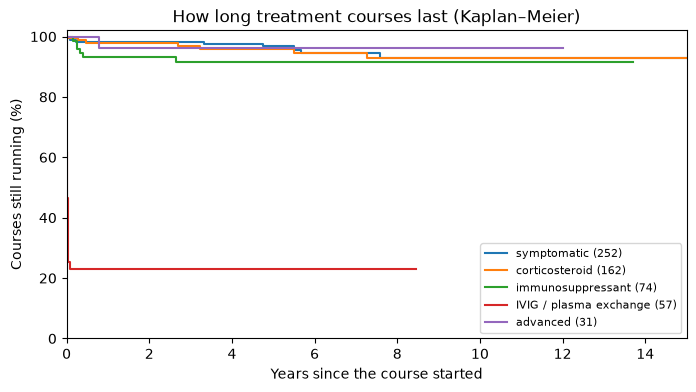

In [21]:
DAYS_PER_YEAR = 365.25
DURATION_CLASSES = ["symptomatic", "corticosteroid", "immunosuppressant", "IVIG / plasma exchange", "advanced"]


def kaplan_meier(years, stopped):
    """Share of courses still running after each duration (a step function up to the longest course)."""
    d = pd.DataFrame({"t": years, "e": stopped})
    curve, share = {0.0: 1.0}, 1.0
    for t in sorted(d.loc[d["e"], "t"].unique()):
        share *= 1 - (d["e"] & d["t"].eq(t)).sum() / d["t"].ge(t).sum()
        curve[t] = share
    curve[max(d["t"].max(), max(curve))] = share
    return pd.Series(curve)


timed = courses[courses["start"].notna() & courses["class"].isin(DURATION_CLASSES)].copy()
censor_time = timed["last_time"].where(
    timed["outcome"].eq("ended, undated"),
    pd.concat([timed["patient"].map(report_date), timed["last_time"]], axis=1).max(axis=1),
)
timed["stopped"] = timed["outcome"].eq("stopped")
timed["years"] = ((timed["end"].where(timed["stopped"], censor_time) - timed["start"]).dt.days / DAYS_PER_YEAR).clip(lower=0)

rows, curves = [], {}
for cls in DURATION_CLASSES:
    c = timed[timed["class"].eq(cls)]
    curve = curves[cls] = kaplan_meier(c["years"], c["stopped"])
    row = {"Class": cls, "Courses": len(c), "Stopped": int(c["stopped"].sum()),
           "Median (years)": curve[curve <= 0.5].index.min()}
    for t in (0.25, 1, 5):
        # Running at t: undefined once no course is followed that long.
        row[f"Running at {t} y (%)"] = 100 * curve[curve.index <= t].iloc[-1] if c["years"].ge(t).any() else None
    rows.append(row)
display(pd.DataFrame(rows).set_index("Class").round(1))

fig, ax = plt.subplots(figsize=(8, 4))
for cls, curve in curves.items():
    ax.step(curve.index, 100 * curve.values, where="post", label=f"{cls} ({len(timed[timed['class'].eq(cls)])})")
ax.set(xlabel="Years since the course started", ylabel="Courses still running (%)",
       title="How long treatment courses last (Kaplan–Meier)", ylim=(0, 102), xlim=(0, 15))
ax.legend(fontsize=8)
plt.show()

### Why periods stop

The end reasons of stopped periods, by class: `EndTreatment` periods, and undated ends whose reason is not *other*. (An undated end with reason *other* is usually a dose change, so it is left out.) A period can have more than one reason; *not given* means the stop has no reason.

In [22]:
stops = periods[
    periods["end_type"].eq("stopped")
    | (periods["end_type"].eq("ended, undated") & periods["end_reasons"].map(lambda r: r != ["other"]))
].join(courses["class"], on="course")
reasons = stops.explode("end_reasons")
reasons["end_reasons"] = reasons["end_reasons"].fillna("not given")
display(
    pd.crosstab(reasons["class"], reasons["end_reasons"], margins=True, margins_name="All")
    .reindex([*CLASS_ORDER, "All"]).dropna(how="all").astype(int)
)

end_reasons,completed_course,lab_abnormality,lack_of_efficacy,not given,other,side_effects,All
class,,,,,,,
symptomatic,1,0,1,3,4,10,19
corticosteroid,0,0,2,2,8,0,12
immunosuppressant,1,7,0,0,4,2,14
thymectomy,28,0,0,19,0,0,47
IVIG / plasma exchange,39,0,0,8,0,0,47
advanced,2,0,0,0,0,0,2
other,39,0,0,10,1,1,51
All,110,7,3,42,17,13,192


### Order of treatment classes

For each patient, the first dated start of each class (*other* left out). The first table gives the order in which patients enter the classes. Classes entered on the same date are joined with "+", since the date cannot order them. The second table looks at each pair of classes among the patients who had both: how often each came first, and how often both started on the same date.

In [23]:
LINE_CLASSES = [c for c in CLASS_ORDER if c != "other"]
first_start = (
    courses[courses["class"].isin(LINE_CLASSES)]
    .groupby(["patient", "class"])["start"].min().dropna()
    .unstack().reindex(columns=LINE_CLASSES)
)


def entry_order(row):
    s = row.dropna().sort_values()
    return " → ".join(" + ".join(sorted(g.index, key=CLASS_ORDER.index)) for _, g in s.groupby(s))


orders = first_start.apply(entry_order, axis=1)
counts = orders.value_counts()
display(pd.concat([
    counts[counts >= MIN_PATIENTS],
    pd.Series({f"other ({(counts < MIN_PATIENTS).sum()} orders)": counts[counts < MIN_PATIENTS].sum()}),
]).rename_axis("Order of first starts").reset_index(name="Patients"))

rows = []
for i, a in enumerate(LINE_CLASSES):
    for b in LINE_CLASSES[i + 1:]:
        both = first_start[[a, b]].dropna()
        if len(both) < MIN_PATIENTS:
            continue
        rows.append({
            "First class (A)": a, "Second class (B)": b, "Patients": len(both),
            "A first (%)": 100 * (both[a] < both[b]).mean(),
            "Same date (%)": 100 * (both[a] == both[b]).mean(),
            "B first (%)": 100 * (both[a] > both[b]).mean(),
        })
display(pd.DataFrame(rows).set_index(["First class (A)", "Second class (B)"]).round(1))

,Order of first starts,Patients
0,symptomatic,84
1,symptomatic → corticosteroid,34
2,symptomatic → corticosteroid → immunosuppressant,19
3,symptomatic → IVIG / plasma exchange,10
4,symptomatic → corticosteroid → advanced,8
5,symptomatic → thymectomy,8
6,corticosteroid → immunosuppressant,6
7,symptomatic → corticosteroid → IVIG / plasma e...,6
8,corticosteroid → symptomatic,5
9,other (61 orders),89


Patients  A first (%)  \
First class (A)        Second class (B)                                
symptomatic            corticosteroid               129         81.4   
                       immunosuppressant             57         94.7   
                       thymectomy                    36         86.1   
                       IVIG / plasma exchange        48         87.5   
                       advanced                      29         93.1   
corticosteroid         immunosuppressant             66         86.4   
                       thymectomy                    26         57.7   
                       IVIG / plasma exchange        32         75.0   
                       advanced                      21        100.0   
immunosuppressant      thymectomy                    16         37.5   
                       IVIG / plasma exchange        13         76.9   
                       advanced                       7        100.0   
thymectomy             IVIG / plasma exchange         7         85.7   
                       advanced                       7        100.0   
IVIG / plasma exchange advanced                       6         66.7   

                                               Same date (%)  B first (%)  
First class (A)        Second class (B)                                    
symptomatic            corticosteroid                    5.4         13.2  
                       immunosuppressant                 0.0          5.3  
                       thymectomy                        2.8         11.1  
                       IVIG / plasma exchange            2.1         10.4  
                       advanced                          0.0          6.9  
corticosteroid         immunosuppressant                 3.0         10.6  
                       thymectomy                        7.7         34.6  
                       IVIG / plasma exchange            3.1         21.9  
                       advanced                          0.0          0.0  
immunosuppressant      thymectomy                        6.2         56.2  
                       IVIG / plasma exchange            0.0         23.1  
                       advanced                          0.0          0.0  
thymectomy             IVIG / plasma exchange            0.0         14.3  
                       advanced                          0.0          0.0  
IVIG / plasma exchange advanced                          0.0         33.3

### Treatment start against diagnosis, and add-on or switch

The first table gives the time from the dated diagnosis milestone to each patient's first start of each class. The second asks, for each patient's first course of a class, whether a course of another class was already running: then the new class was added on. Otherwise it was a first treatment or a switch. A course runs from its start to its stop; a course that ended on an undated date counts as running until its last dated event.

In [24]:
diagnosis = wide["time"]["DIAGNOSIS"].reindex(first_start.index)
rows = []
for cls in LINE_CLASSES:
    gap = ((first_start[cls] - diagnosis).dt.days / DAYS_PER_MONTH).dropna()
    rows.append({
        "Class": cls, "Patients": len(gap),
        "Median (months)": gap.median(), "Q1": gap.quantile(0.25), "Q3": gap.quantile(0.75),
        "Before diagnosis (%)": 100 * (gap < 0).mean(),
    })
display(pd.DataFrame(rows).set_index("Class").round(1))

line = courses[courses["class"].isin(LINE_CLASSES) & courses["start"].notna()].copy()
line["until"] = line["end"].fillna(
    line["last_time"].where(line["outcome"].eq("ended, undated"), line["patient"].map(report_date))
)


def context(first):
    others = line[line["patient"].eq(first["patient"]) & line["class"].ne(first["class"])]
    if (others["start"].lt(first["start"]) & others["until"].gt(first["start"])).any():
        return "added on"
    if others["start"].eq(first["start"]).any():
        return "same date as another class"
    return "first treatment or switch"


firsts = line.sort_values("start").groupby(["patient", "class"]).head(1)
firsts["context"] = firsts.apply(context, axis=1)
display(
    pd.crosstab(firsts["class"], firsts["context"])
    .reindex(index=LINE_CLASSES, columns=["added on", "same date as another class", "first treatment or switch"], fill_value=0)
)

,Patients,Median (months),Q1,Q3,Before diagnosis (%)
Class,,,,,
symptomatic,248,0.1,0.0,1.0,16.1
corticosteroid,146,3.0,1.5,5.0,3.4
immunosuppressant,66,10.6,7.1,13.7,0.0
thymectomy,38,6.4,3.0,11.8,0.0
IVIG / plasma exchange,51,15.0,5.0,29.0,0.0
advanced,31,33.0,22.0,40.7,0.0


context,added on,same date as another class,first treatment or switch
class,,,
symptomatic,19,9,222
corticosteroid,105,7,35
immunosuppressant,64,0,3
thymectomy,34,1,5
IVIG / plasma exchange,44,1,8
advanced,30,0,1


## Step 4: Object-centric view

This step looks at the fact events from the three perspectives of the log: `Patient`, `PatientCondition` and `TreatmentCourse`. Milestones are left out because they summarise the facts (step 2).

### Which objects an event touches

Each fact event relates to its subject (the fact object, such as a `Treatment` or a `Symptom`), to its `Patient`, and through the subject's links to a `PatientCondition` and a `TreatmentCourse`. The first table lists the combinations of object types events relate to. The second gives, per activity, the share of events that reach each perspective. An event without a `PatientCondition` comes from a fact the sources did not tie to any condition.

In [25]:
PERSPECTIVES = ["Patient", "PatientCondition", "TreatmentCourse"]
FACT_ACTIVITIES = sorted(events.loc[events["kind"].eq("fact"), ACT].unique())

facts_all_types = pm4py.filter_ocel_event_attribute(ocel, ACT, FACT_ACTIVITIES)
fact_rel = facts_all_types.relations

combos = fact_rel.groupby(EID)[OTYPE].agg(lambda s: " + ".join(sorted(set(s))))
display(combos.value_counts().rename_axis("Object types of an event").reset_index(name="Events"))

n_events = facts_all_types.events[ACT].value_counts()
has_type = fact_rel.drop_duplicates([EID, OTYPE])
reach = (
    pd.crosstab(has_type[ACT], has_type[OTYPE])
    .reindex(columns=PERSPECTIVES, fill_value=0)
    .div(n_events, axis=0).mul(100).round(1)
    .add_suffix(" (%)")
)
reach.insert(0, "Events", n_events)
display(reach.sort_values("Events", ascending=False))

condition_rel = fact_rel[fact_rel[OTYPE].eq("PatientCondition")]
display({"Fact events with more than one PatientCondition": int(condition_rel.groupby(EID).size().gt(1).sum())})

,Object types of an event,Events
0,Patient + PatientCondition + Treatment + Treat...,1899
1,HcpVisit + Patient,1593
2,Patient + Symptom,825
3,HcpVisit + Patient + PatientCondition,783
4,DiagnosticProcedure + Patient + PatientCondition,634
5,Diagnosis + Patient + PatientCondition,624
6,Patient + PatientCondition + Symptom,500
7,DiagnosticProcedure + Patient,334
8,AdverseEvent + Patient,260
9,Patient + PatientCondition + Treatment,242


ocel:type,Events,Patient (%),PatientCondition (%),TreatmentCourse (%)
ocel:activity,,,,
VisitHcp,2376,100.0,33.0,0.0
StartTreatment,1604,100.0,93.9,86.0
StartSymptom,1087,100.0,36.8,0.0
UndergoDiagnosticProcedure,968,100.0,65.5,0.0
ReceiveDiagnosis,644,100.0,96.9,0.0
ChangeTreatment,500,100.0,99.0,98.6
StartAdverseEvent,368,100.0,32.3,0.0
EndSymptom,232,100.0,41.8,0.0
EndTreatment,182,100.0,76.9,92.9


{'Fact events with more than one PatientCondition': 30}

### The three perspectives compared

For each perspective: its objects, the share of fact events it sees, and what its directly-follows graph (from PM4Py's object-centric DFG) rests on. *Tied pairs*: consecutive events of an object with the same timestamp, which PM4Py orders arbitrarily. *Unique sequence*: objects whose sequence of activities no other object shares (ties broken by activity name). `OC_MIN_OBJECTS` is the threshold used for the map below. `PatientCondition` objects include each patient's other conditions (thymoma, asthma, ...), not only myasthenia gravis.

In [26]:
OC_MIN_OBJECTS = 80  # show activities and edges of at least this many objects in the map below

facts_ocel = pm4py.filter_ocel_object_types(facts_all_types, PERSPECTIVES)
ocdfg = pm4py.discover_ocdfg(facts_ocel)

rel = facts_ocel.relations.sort_values([OID, TS, ACT])
rel["next_ts"] = rel.groupby(OID)[TS].shift(-1)
sequences_by_object = rel.groupby([OTYPE, OID])[ACT].agg(tuple)

rows = []
for ot in PERSPECTIVES:
    r = rel[rel[OTYPE].eq(ot)]
    pairs = r.dropna(subset=["next_ts"])
    seqs = sequences_by_object.loc[ot]
    edges = ocdfg["edges"]["unique_objects"][ot]  # edge -> objects that have it
    rows.append({
        "Perspective": ot,
        "Objects": len(seqs),
        "Fact events seen (%)": 100 * r[EID].nunique() / len(facts_ocel.events),
        "Events per object (median)": seqs.map(len).median(),
        "Directly-follows pairs": len(pairs),
        "Tied pairs (%)": 100 * pairs[TS].eq(pairs["next_ts"]).mean(),
        "Distinct edges": len(edges),
        f"Edges in ≥ {OC_MIN_OBJECTS} objects": sum(len(objs) >= OC_MIN_OBJECTS for objs in edges.values()),
        "Unique sequence (%)": 100 * seqs.map(seqs.value_counts()).eq(1).mean(),
    })
display(pd.DataFrame(rows).set_index("Perspective").round(1))

,Objects,Fact events seen (%),Events per object (median),Directly-follows pairs,Tied pairs (%),Distinct edges,Edges in ≥ 80 objects,Unique sequence (%)
Perspective,,,,,,,,
Patient,280,100.0,28.0,8084,31.0,159,25,100.0
PatientCondition,642,61.5,3.0,4535,30.8,143,12,49.1
TreatmentCourse,705,24.4,2.0,1337,29.9,7,4,5.2


### Object-centric directly-follows graph

One graph per perspective, drawn together; edge colour gives the perspective. Numbers count objects (UO, unique objects): an edge labelled `Patient UO=120` occurs in 120 patients. Only activities and edges of at least `OC_MIN_OBJECTS` objects are shown, since the full graph is unreadable. With about 30% of consecutive events tied, many edges in both directions between two activities (e.g. `VisitHcp` ⇄ `UndergoDiagnosticProcedure`) say *same month* rather than *one before the other*.

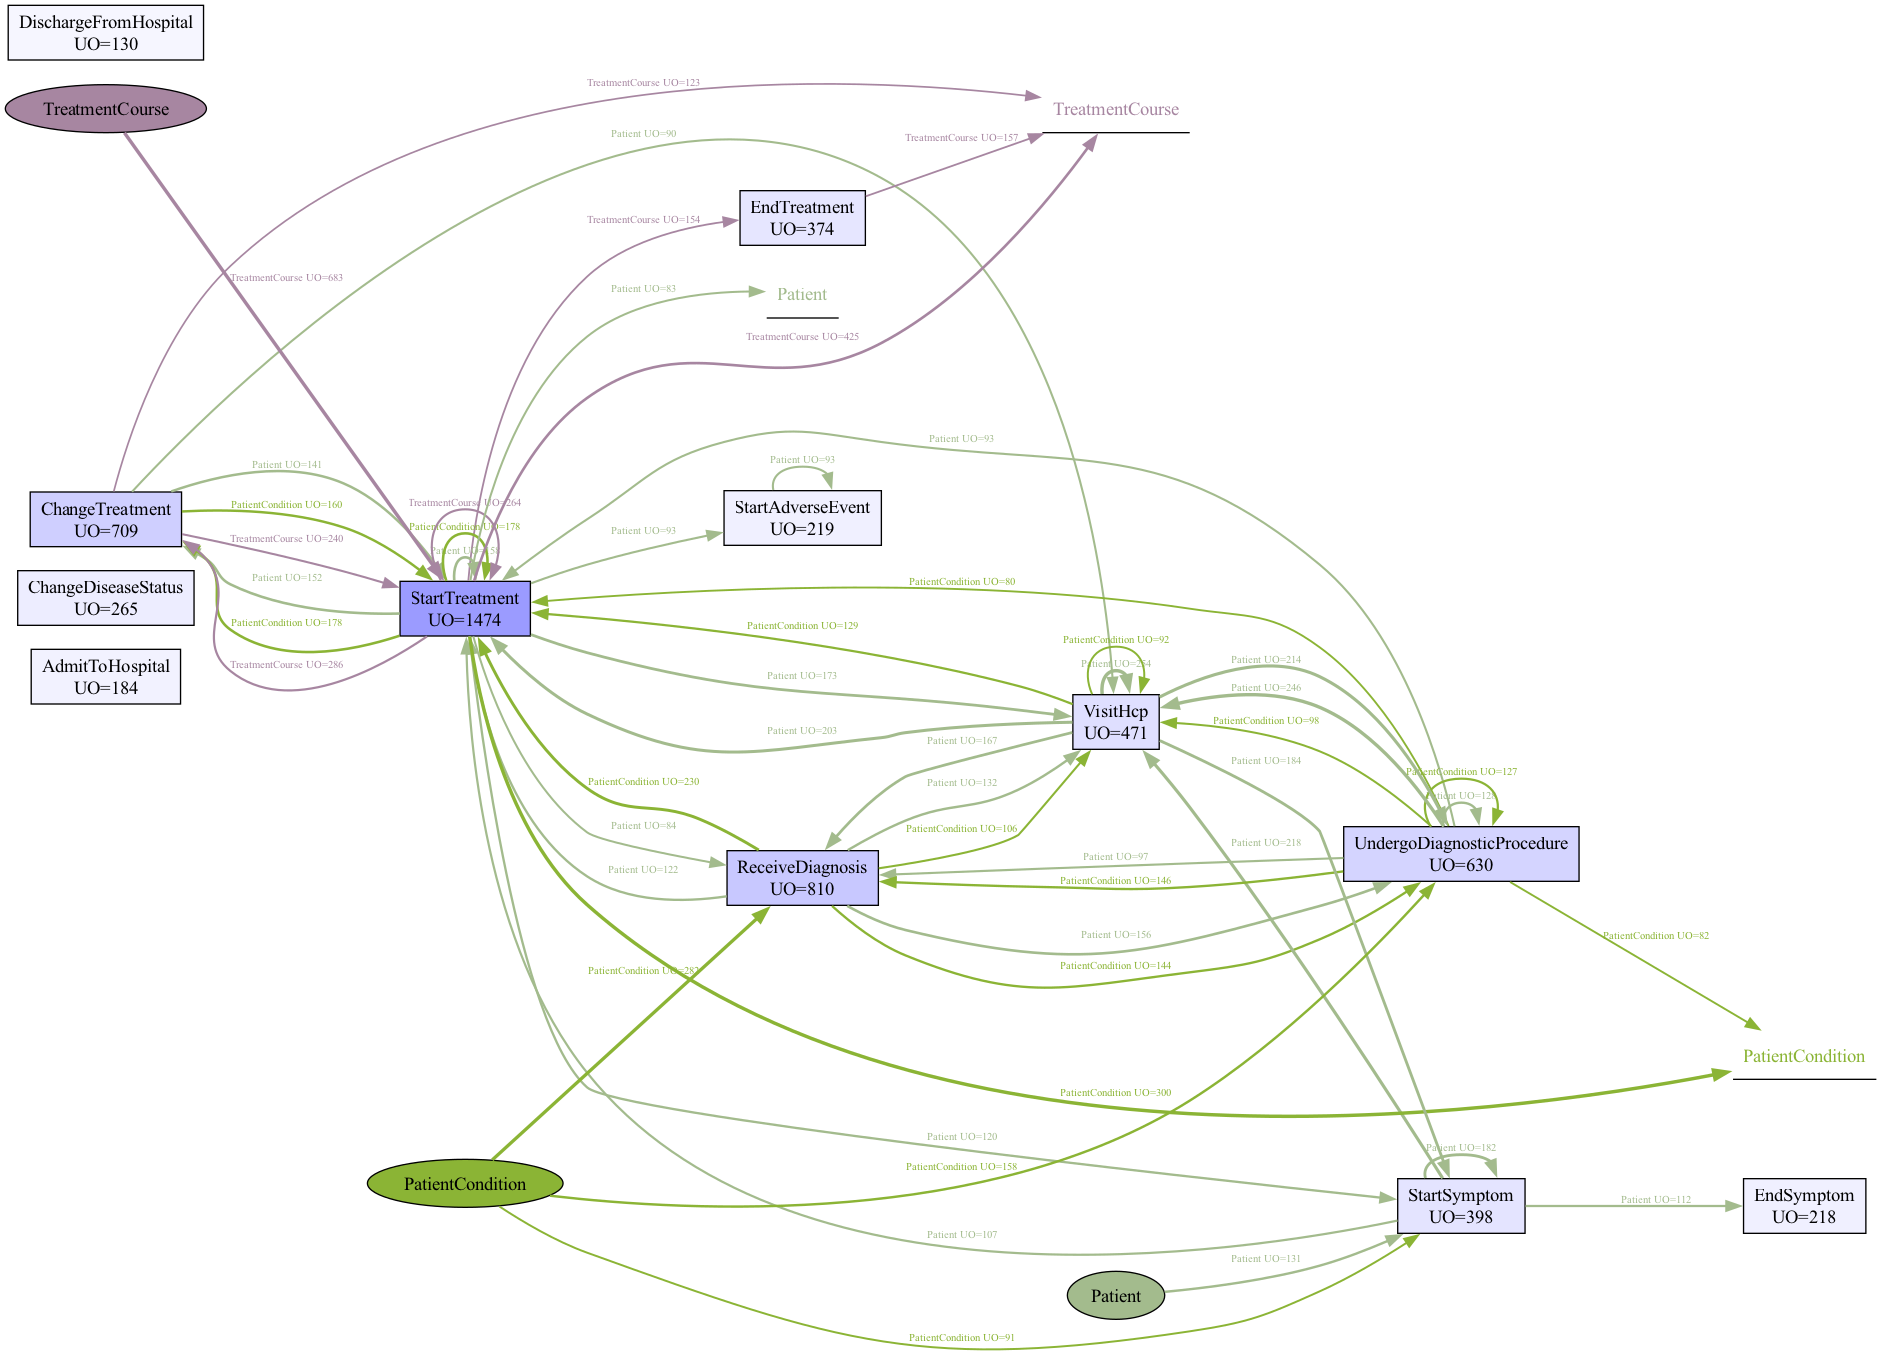

In [27]:
# PNG, not SVG: in a notebook PM4Py displays graphs through IPython's Image, which needs a raster format.
pm4py.view_ocdfg(
    ocdfg,
    annotation="frequency",
    act_metric="unique_objects",
    edge_metric="unique_objects",
    act_threshold=OC_MIN_OBJECTS,
    edge_threshold=OC_MIN_OBJECTS,
    format="png",
)

### Treatment courses on their own

The `TreatmentCourse` perspective sees only `StartTreatment`, `ChangeTreatment` and `EndTreatment`, so its graph and Petri net are small enough to read. They show the period lifecycle of step 3, with one catch: PM4Py orders a course's events by timestamp alone. A change and the next period's start often share a timestamp, and sometimes the next start is dated before the change, so edges such as `ChangeTreatment` → `ChangeTreatment` and part of `StartTreatment` → `StartTreatment` come from ordering, not from the course. The table counts how often this happens. Step 3's lifecycles order events by period and avoid it.

The Petri net is discovered with the inductive miner. On all three perspectives it is too large to read; to see it anyway, run `pm4py.view_ocpn(pm4py.discover_oc_petri_net(facts_ocel))`.

{'Changes followed by a dated period': 470,
 'Next period starts at the same timestamp (%)': np.float64(36.4),
 'Next period starts before the change (%)': np.float64(10.0)}

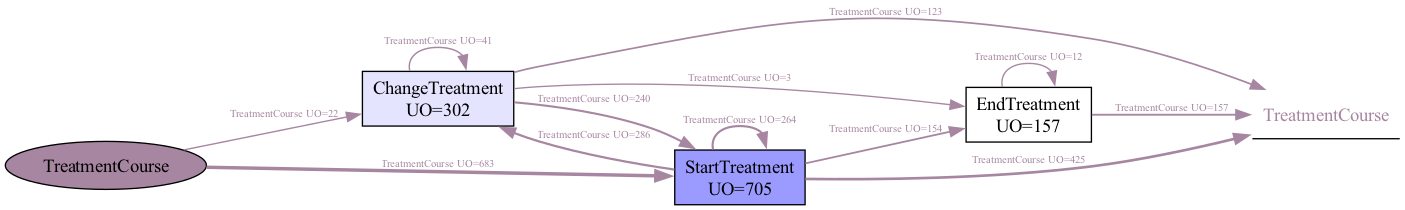

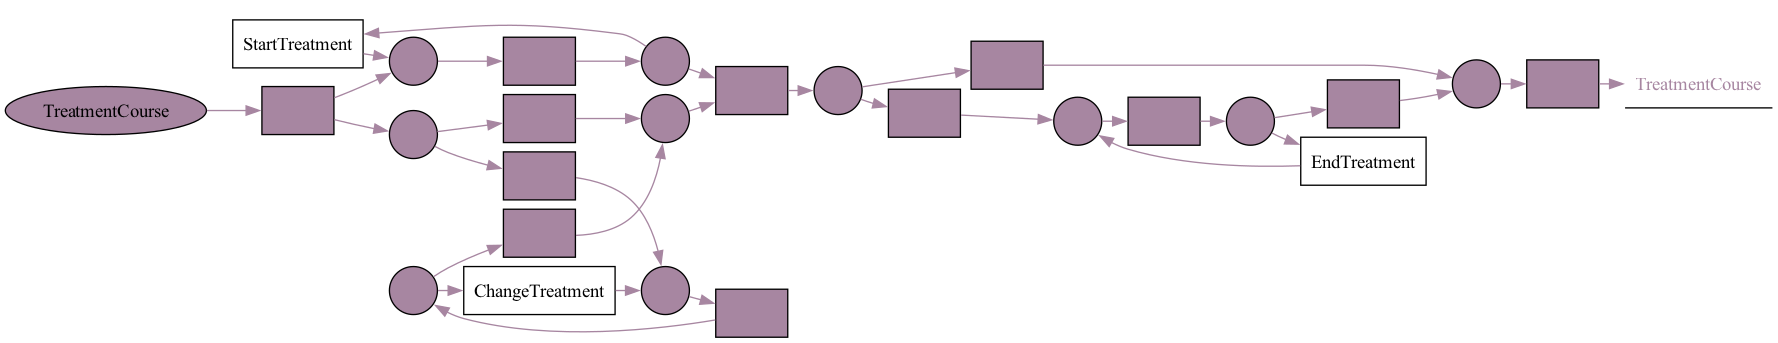

In [28]:
p = periods.assign(next_start=periods.groupby("course")["start"].shift(-1))
changes = p[p["end_type"].eq("changed") & p["next_start"].notna()]
display({
    "Changes followed by a dated period": len(changes),
    "Next period starts at the same timestamp (%)": round(100 * changes["end"].eq(changes["next_start"]).mean(), 1),
    "Next period starts before the change (%)": round(100 * changes["next_start"].lt(changes["end"]).mean(), 1),
})

course_ocel = pm4py.filter_ocel_event_attribute(
    pm4py.filter_ocel_object_types(facts_ocel, ["TreatmentCourse"]),
    ACT, ["StartTreatment", "ChangeTreatment", "EndTreatment"],
)
pm4py.view_ocdfg(
    pm4py.discover_ocdfg(course_ocel),
    annotation="frequency", act_metric="unique_objects", edge_metric="unique_objects", format="png",
)
pm4py.view_ocpn(pm4py.discover_oc_petri_net(course_ocel), format="png")

## Step 5: Measures for the evaluation

The measures the paper's evaluation reports beside steps 1–4: what a case-centric log loses when courses run side by side, how far events can be traced to their sources (R1), how many terms are normalized (R3), and whether both logs conform to the OCEL 2.0 JSON format. What the mapping turns into events, and why the rest does not become one, is in the build report (`logs/cohort-quality.md`, *Not mapped*).

### Courses running side by side

A case-centric analysis of patient journeys takes the patient as the case: the `Patient` row of the perspectives table in step 4. In that log, a treatment event can be assigned to its course by its order only if no other course of the patient is running at the time. This cell counts the treatment events for which another course is running. A course runs as in step 3: from its first start to its stop; to its last dated event when it ended on an undated date; and, when no end is recorded, as below. A course with no end recorded may still be running or may have ended without a date, so it is counted both ways: *Lower bound*, it runs to its last dated event; *Upper bound*, it runs to the patient's report date. Courses without a dated start are left out.

In [29]:
running = courses[courses["start"].notna()].copy()
running["until_lower"] = running["end"].fillna(running["last_time"])
running["until_upper"] = running["end"].fillna(
    running["last_time"].where(running["outcome"].eq("ended, undated"), running["patient"].map(report_date))
)
course_of_period = periods.set_index("period")["course"]

rows = []
for e in raw["events"]:
    if e["type"] not in ("StartTreatment", *END_EVENT):
        continue
    course = course_of_period.get(related(e, "subject")[0])
    if course is None:  # medication outside the MG journey: in no course
        continue
    t = pd.Timestamp(e["time"])
    patient = courses.at[course, "patient"]
    others = running[running["patient"].eq(patient) & (running.index != course)]
    started = others["start"].le(t)
    rows.append({
        "activity": e["type"],
        "patient": patient,
        "Lower bound": bool((started & others["until_lower"].ge(t)).any()),
        "Upper bound": bool((started & others["until_upper"].ge(t)).any()),
    })
concurrent = pd.DataFrame(rows)

BOUNDS = ["Lower bound", "Upper bound"]
counts = concurrent.groupby("activity")[BOUNDS].sum()
counts.loc["all"] = counts.sum()
size = concurrent.groupby("activity").size()
size.loc["all"] = size.sum()
side_by_side = counts.div(size, axis=0).mul(100).round(1).add_suffix(" (%)")
side_by_side.insert(0, "Treatment events", size)
display(side_by_side)
display({
    "Patients with a course": int(concurrent["patient"].nunique()),
    **{f"Patients with a treatment event while another course runs ({b.lower()})":
       int(concurrent.loc[concurrent[b], "patient"].nunique()) for b in BOUNDS},
})

,Treatment events,Lower bound (%),Upper bound (%)
activity,,,
ChangeTreatment,493,37.9,66.7
EndTreatment,169,71.6,88.2
StartTreatment,1380,42.2,64.1
all,2042,43.6,66.7


{'Patients with a course': 270,
 'Patients with a treatment event while another course runs (lower bound)': 157,
 'Patients with a treatment event while another course runs (upper bound)': 196}

### Traceability (R1)

A fact event is traceable if it or its subject carries evidence references (`evidence_refs`) and the provenance log has an assertion of that fact (`AssertFact`, `ReviseFact`) quoting at least one source: a message, a document or an onboarding answer or session. The fact behind an event is named in the event's identifier (`e:<patient>:<fact>`, the fact is `ce:<patient>:<fact>`): a change event such as `ChangeDiseaseStatus` has the changed object as its subject, not its fact. Milestone events are left out: the export gives only how many facts support a milestone, not which ones. The three facts of patient S184 that were revised and whose first assertion has no time have no assertion in the provenance log (build report, *Not mapped*).

In [30]:
PROVENANCE_PATH = LOG_PATH.with_name(LOG_PATH.name.replace("-journey", "-provenance"))
prov = json.loads(PROVENANCE_PATH.read_text())

SOURCE_TYPES = {"Message", "Document", "OnboardingAnswer", "OnboardingSession"}
prov_type = {o["id"]: o["type"] for o in prov["objects"]}
sources_of_fact = {}  # fact id -> source objects its assertions quote
for e in prov["events"]:
    if e["type"] in ("AssertFact", "ReviseFact"):
        quoted = {s for s in related(e, "quotes") if prov_type.get(s) in SOURCE_TYPES}
        for fact in related(e, "subject"):
            sources_of_fact.setdefault(fact, set()).update(quoted)

object_type = {o["id"]: o["type"] for o in raw["objects"]}
object_attrs = {o["id"]: attrs(o) for o in raw["objects"]}

rows = []
for e in raw["events"]:
    if e["type"].startswith("Reach"):
        continue
    _, patient_code, fact_code = e["id"].split(":")[:3]
    fact = f"ce:{patient_code}:{fact_code}"
    subject = (related(e, "subject") or [None])[0]
    rows.append({
        "activity": e["type"],
        "evidence refs": bool(attrs(e).get("evidence_refs") or (subject and object_attrs[subject].get("evidence_refs"))),
        "asserted": fact in sources_of_fact,
        "quotes a source": bool(sources_of_fact.get(fact)),
    })
trace = pd.DataFrame(rows)
trace["traceable"] = trace["evidence refs"] & trace["quotes a source"]

display(trace.drop(columns="activity").mean().mul(100).round(1).rename("Fact events (%)").to_frame())
if not trace["traceable"].all():
    display(trace.loc[~trace["traceable"], "activity"].value_counts().rename("Not traceable"))
display({"Fact events": len(trace), "Traceable": int(trace["traceable"].sum())})

,Fact events (%)
evidence refs,100.0
asserted,100.0
quotes a source,100.0
traceable,100.0


activity
StartSymptom      2
StartTreatment    1
Name: Not traceable, dtype: int64

{'Fact events': 8364, 'Traceable': 8361}

### Normalized terminology (R3)

The share of fact events whose fact has a specific code from the shared vocabulary, rather than a catch-all code (`*.other`, the `catch_all_pattern` of `pj2ocel/mapping.yaml`) or no code. `TERM` names the attribute holding the code for each fact type that has one. *Shared* counts the specifically coded events whose code also occurs in another patient's journey: these are the events a cohort can be compared on.

In [31]:
CATCH_ALL = r"\.other(?:_[a-z0-9_]+)?$"  # catch_all_pattern of pj2ocel/mapping.yaml, without capturing
TERM = {
    "Treatment": "treatment_name", "Symptom": "symptom_name", "Diagnosis": "condition_name",
    "DiagnosticProcedure": "test_name", "AdverseEvent": "experience", "HcpVisit": "hcp_specialty",
}
patient_of_event = events.set_index(EID)["patient"]

rows = []
for e in raw["events"]:
    subject = (related(e, "subject") or [None])[0]
    kind = object_type.get(subject)
    if e["type"].startswith("Reach") or kind not in TERM:
        continue
    rows.append({"type": kind, "patient": patient_of_event[e["id"]], "code": object_attrs[subject].get(TERM[kind])})
terms = pd.DataFrame(rows)
is_catch_all = terms["code"].fillna("").str.contains(CATCH_ALL, regex=True)
terms["coding"] = "specific"
terms.loc[is_catch_all, "coding"] = "catch-all"
terms.loc[terms["code"].isna() | terms["code"].eq(""), "coding"] = "no code"

patients_per_code = terms[terms["coding"].eq("specific")].groupby("code")["patient"].nunique()
terms["shared"] = terms["coding"].eq("specific") & terms["code"].map(patients_per_code).gt(1)

coding = pd.crosstab(terms["type"], terms["coding"], margins=True, margins_name="all")
coding = coding.reindex(columns=["specific", "catch-all", "no code", "all"], fill_value=0)
coding["Specific (%)"] = (100 * coding["specific"] / coding["all"]).round(1)
shared = terms.groupby("type")["shared"].sum()
shared.loc["all"] = terms["shared"].sum()
coding["Shared (%)"] = (100 * shared / coding["all"]).round(1)
display(coding)
display({
    "Fact events of types with a code": len(terms),
    "Fact types without a code": sorted(
        set(object_type[(related(e, "subject") or [None])[0]] for e in raw["events"]
            if not e["type"].startswith("Reach") and related(e, "subject")) - set(TERM)
    ),
    "Distinct specific codes": int(patients_per_code.size),
})

coding,specific,catch-all,no code,all,Specific (%),Shared (%)
type,,,,,,
AdverseEvent,274,111,0,385,71.2,70.4
Diagnosis,610,34,0,644,94.7,94.7
DiagnosticProcedure,768,200,0,968,79.3,78.9
HcpVisit,2239,11,126,2376,94.2,94.2
Symptom,1247,78,0,1325,94.1,93.8
Treatment,2220,66,0,2286,97.1,97.0
all,7358,500,126,7984,92.2,92.0


{'Fact events of types with a code': 7984,
 'Fact types without a code': ['DiseaseStatus',
  'Hospitalization',
  'InformationSearch',
  'PatientCondition'],
 'Distinct specific codes': 121}

### Conformance to the OCEL 2.0 JSON format

Both logs are checked against the rules of the OCEL 2.0 JSON format: the four top-level lists; unique type names and identifiers; every event and object of a declared type; every attribute declared for its type, with a value of the declared type and, on objects, a time; ISO 8601 times; every relationship pointing to an existing object. A count of 0 means the rule holds. PM4Py then reads both logs.

In [32]:
FORMAT_RULES = [
    "top-level lists other than objectTypes, eventTypes, objects, events",
    "duplicate names in objectTypes", "duplicate names in eventTypes",
    "duplicate object ids", "duplicate event ids",
    "objects of an undeclared type", "events of an undeclared type",
    "object attributes not declared for the type", "event attributes not declared for the type",
    "object attribute values not of the declared type", "event attribute values not of the declared type",
    "object attribute values without an ISO 8601 time", "events without an ISO 8601 time",
    "object relationships to a missing object", "event relationships to a missing object",
    "object relationships without a qualifier", "event relationships without a qualifier",
]


def format_violations(log):
    v = Counter({rule: 0 for rule in FORMAT_RULES})
    v["top-level lists other than objectTypes, eventTypes, objects, events"] = len(
        set(log) ^ {"objectTypes", "eventTypes", "objects", "events"})
    declared = {}
    for kind in ("objectTypes", "eventTypes"):
        names = [t["name"] for t in log[kind]]
        v[f"duplicate names in {kind}"] = len(names) - len(set(names))
        declared[kind] = {t["name"]: {a["name"]: a["type"] for a in t.get("attributes", [])} for t in log[kind]}
    object_ids = {o["id"] for o in log["objects"]}
    v["duplicate object ids"] = len(log["objects"]) - len(object_ids)
    v["duplicate event ids"] = len(log["events"]) - len({e["id"] for e in log["events"]})

    def is_time(value):
        try:
            pd.Timestamp(value)
            return isinstance(value, str)
        except (ValueError, TypeError):
            return False

    def fits(value, kind):
        if kind == "boolean":
            return isinstance(value, bool)
        if kind == "integer":
            return isinstance(value, int) and not isinstance(value, bool)
        if kind == "float":
            return isinstance(value, (int, float)) and not isinstance(value, bool)
        if kind == "time":
            return is_time(value)
        return isinstance(value, str)

    for kind, items in (("objectTypes", log["objects"]), ("eventTypes", log["events"])):
        what = "object" if kind == "objectTypes" else "event"
        for item in items:
            types = declared[kind]
            if item["type"] not in types:
                v[f"{what}s of an undeclared type"] += 1
                continue
            for a in item.get("attributes", []):
                if a["name"] not in types[item["type"]]:
                    v[f"{what} attributes not declared for the type"] += 1
                elif not fits(a["value"], types[item["type"]][a["name"]]):
                    v[f"{what} attribute values not of the declared type"] += 1
                if what == "object" and not is_time(a.get("time")):
                    v["object attribute values without an ISO 8601 time"] += 1
            if what == "event" and not is_time(item.get("time")):
                v["events without an ISO 8601 time"] += 1
            for r in item.get("relationships", []):
                v[f"{what} relationships to a missing object"] += r["objectId"] not in object_ids
                v[f"{what} relationships without a qualifier"] += not isinstance(r.get("qualifier"), str)
    assert set(v) == set(FORMAT_RULES), set(v) ^ set(FORMAT_RULES)
    return v


checks = pd.DataFrame({LOG_PATH.name: format_violations(raw), PROVENANCE_PATH.name: format_violations(prov)}).loc[FORMAT_RULES]
display(checks)

prov_ocel = pm4py.read_ocel2_json(str(PROVENANCE_PATH))
display({
    f"PM4Py reads {LOG_PATH.name}": f"{len(ocel.events)} events, {len(ocel.objects)} objects",
    f"PM4Py reads {PROVENANCE_PATH.name}": f"{len(prov_ocel.events)} events, {len(prov_ocel.objects)} objects",
})

,cohort-journey.ocel.json,cohort-provenance.ocel.json
"top-level lists other than objectTypes, eventTypes, objects, events",0,0
duplicate names in objectTypes,0,0
duplicate names in eventTypes,0,0
duplicate object ids,0,0
duplicate event ids,0,0
objects of an undeclared type,0,0
events of an undeclared type,0,0
object attributes not declared for the type,0,0
event attributes not declared for the type,0,0
object attribute values not of the declared type,0,0


{'PM4Py reads cohort-journey.ocel.json': '10364 events, 10935 objects',
 'PM4Py reads cohort-provenance.ocel.json': '29179 events, 30553 objects'}